# Demo: DESI Legacy Stacked PSF

In [1]:
import sys
import os, numpy as np, time
import matplotlib.pyplot as plt
from astropy.io import fits, ascii
from astropy.table import Table
from astropy.visualization import simple_norm
from IPython.display import Image, display
sys.path.append("/home/yangxinlai/Software/my_code")
sys.path.append("/home/yangxinlai/Software/GalfitX-main")
sys.path.append("/home/yangxinlai/Software/astro_image_mask_tools-main/src")
from psf_tools.selection import (select_valid_stars, subtract_background, cutout_stars, stacked_psf_pipeline, gaia_crossmatch)
from psf_tools.plotting import plot_background, plot_segment
from masktools import mask_poly_expand          # This is a tool to expand mask from Shangguan.
from galfitx.source_detection import SExtractor
%matplotlib inline
print("Ready.")

The SFD'98 dust map is not in the data directory:

    /home/yangxinlai/.dustmaps

To change the data directory, call:

    from dustmaps.config import config
    config['data_dir'] = '/path/to/data/directory'

To download the SFD'98 map to the data directory, call:

    import dustmaps.sfd
    dustmaps.sfd.fetch()

Ready.


## Configuration

In [2]:
DATA_DIR = "./demo_data"
SCI_IMAGE = os.path.join(DATA_DIR, "image_r.fits")              # Image file for SExtractor and stacked PSF.
WHT_FILE  = os.path.join(DATA_DIR, "wht_r.fits")                # Weight file for SExtractor.
OUTPUT_DIR = "./output"                                         # Output dir for results.
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Image metadata
PIXEL_SCALE   = 0.262         # arcsec / pixel, depending apon the data
MAG_ZEROPOINT = 22.5          
FWHM_ARCSEC   = 1.5           # ** FWHM of the image, it directly affect the `class_star' parameter and is crutial for selecting stars candidates **.
                              # For ground-based telescope, we can choose 1.0 – 1.5.

# Star candidates selection criterian
COMBINED_FLAGS_LIMIT = 1      # Select stars with combined flags = 0. If change to 2, then we'll select stars with flags = 0 / 1.
ELONG_LIMIT   = 1.2           # Select stars with elongation < 1.2.
CLASS_STAR_LIMIT = 0.9        # Select stars with class_star > 0.9.
MAG_BRIGHT    = 17.0          # Select stars with mag > 17.0.
MAG_FAINT     = 22.0          # Select stars with mag < 22.0.
SNR_LIMIT     = 0.0           # Select stars with no SNR limits, because in this field, all stars that we selected have high SNR.
SKIP_NEIGHBORS = True         # If true, skip the stars with bright neighbors in the cutout.
MAG_GAP_LIMIT = 2.0           # Remove star candidates which have close contaminations which are 2 magnitude brighter than the target star.

# PSF associated parameters
CUTOUT_SIZE   = 95            # Cutout size in pixels. We select the stars whose cutouts are fully within the image.
OVERSAMPLING  = 3             # Oversampling factor for stacked PSF.
print(f"Criteria: elong<{ELONG_LIMIT}, class_star>{CLASS_STAR_LIMIT}, "
      f"combined_flags<{COMBINED_FLAGS_LIMIT}, mag {MAG_BRIGHT}-{MAG_FAINT}, SNR>{SNR_LIMIT}")

# Detection parameters
DETECT_THRESH   = 1.2
DETECT_MINAREA  = 10           # Parameters for source detection.
DEBLEND_NTHRESH = 32
DEBLEND_MINCONT = 0.003        # Parameters for deblending.
KERNEL_FILE = "./gauss_4.0_7x7.conv"            # Convolution kernel for SExtractor. You can use the default one, or create your own.
SEX_KERNEL  = np.loadtxt(KERNEL_FILE, skiprows=1)
print(f"SExtractor: thresh={DETECT_THRESH}, minarea={DETECT_MINAREA}, "
      f"deblend nthresh={DEBLEND_NTHRESH}, deblend mincont={DEBLEND_MINCONT}")

# Background subtraction
BKG_BOX_SIZE    = 16
BKG_FILTER_SIZE = (3, 3)

Criteria: elong<1.2, class_star>0.9, combined_flags<1, mag 17.0-22.0, SNR>0.0
SExtractor: thresh=1.2, minarea=10, deblend nthresh=32, deblend mincont=0.003


## Look at The Original Image

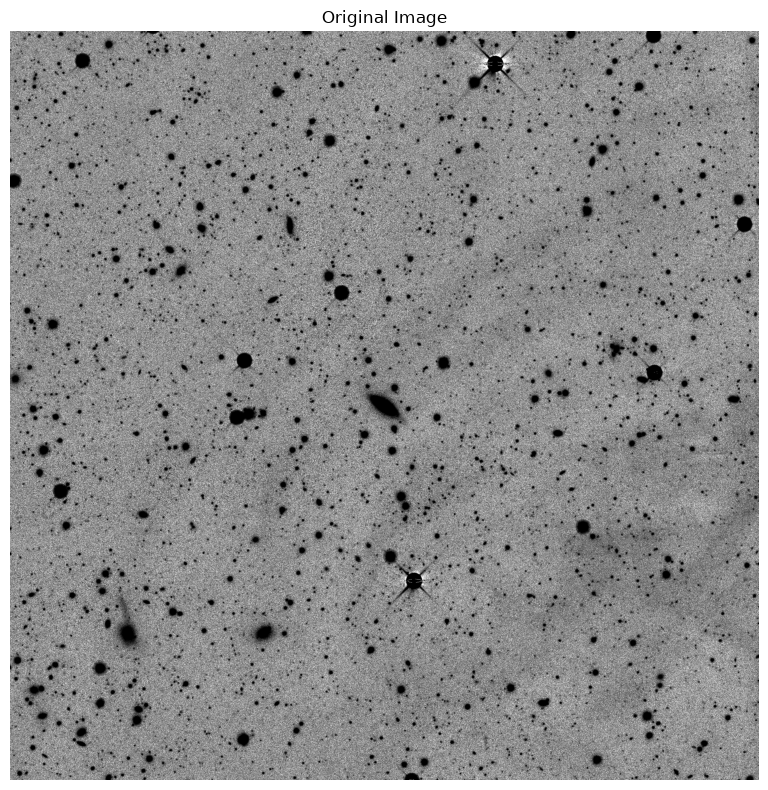

In [3]:
### Insepct your data, the astronomical images usually have sky background.
sci_orig = fits.getdata(SCI_IMAGE)
fig, ax = plt.subplots(figsize=(8, 8))
vmin, vmax = np.percentile(sci_orig, 3), np.percentile(sci_orig, 98)
norm = simple_norm(sci_orig, 'asinh', vmin=vmin, vmax=vmax)
ax.imshow(sci_orig, norm=norm, origin='lower', cmap='Greys')
ax.set_title('Original Image')
ax.axis('off')
plt.tight_layout()
plt.show()

## 1st SExtractor — On Original Image
This step detects sources on the original image. We'll later use the segmentation map to generate a source mask for background subtraction.

In [4]:
# Define output directories for SExtractor results
RAW_SEX_DIR = os.path.join(OUTPUT_DIR, "SEx_raw")
os.makedirs(RAW_SEX_DIR, exist_ok=True)
RAW_CAT_FILE = os.path.join(RAW_SEX_DIR, "sex_out.cat")
RAW_SEG_FILE = os.path.join(RAW_SEX_DIR, "sex_out_seg.fits")

# Clip negative weights → save to file for SExtractor
wht = fits.getdata(WHT_FILE)
wht_new = wht.copy()
wht_new[wht_new <= 0] = 0.          # Clip negative weights to 0, if any exist.
WHT_CLIP_FILE = os.path.join(OUTPUT_DIR, "wht_clip.fits")
fits.writeto(WHT_CLIP_FILE, wht_new, fits.getheader(WHT_FILE), overwrite=True)

# Run source detection with galfitx.SExtractor
catalog_raw, segm_raw, src_cat_raw = SExtractor(
    filename=SCI_IMAGE,
    catalog_name=RAW_CAT_FILE,
    kernel=SEX_KERNEL,
    detect_minarea=DETECT_MINAREA,
    detect_thresh=DETECT_THRESH,
    deblend=True,
    deblend_nthresh=DEBLEND_NTHRESH,
    deblend_mincont=DEBLEND_MINCONT,
    clean=True,
    back_type=False,
    weight_type='MAP_WEIGHT',
    weight_name=WHT_CLIP_FILE,
    mag_zeropoint=MAG_ZEROPOINT,
    pixel_scale=PIXEL_SCALE,
    fwhm_arcsec=FWHM_ARCSEC,
    verbose=True,
)
hdr = fits.getheader(SCI_IMAGE)
seg_data_raw = segm_raw.data.astype(np.int32)
fits.writeto(RAW_SEG_FILE, seg_data_raw, hdr, overwrite=True)
print(f"1st SEx segmentation saved to {RAW_SEG_FILE}")

[GX_CSEG] background 0.33s  var_setup 0.00s  ring_alloc 0.00s  scan 1.79s  segpaint 0.01s  labelstats 0.01s  outputs 0.11s
[GX_CSEG] 3510 detections -> 3209 objects
[GX_CSEG] assembled 3209 objects -> ./output/SEx_raw/sex_out.cat
1st SEx segmentation saved to ./output/SEx_raw/sex_out_seg.fits


## Plot Segmentation

Segment plot saved to ./output/segment_plot_raw.png


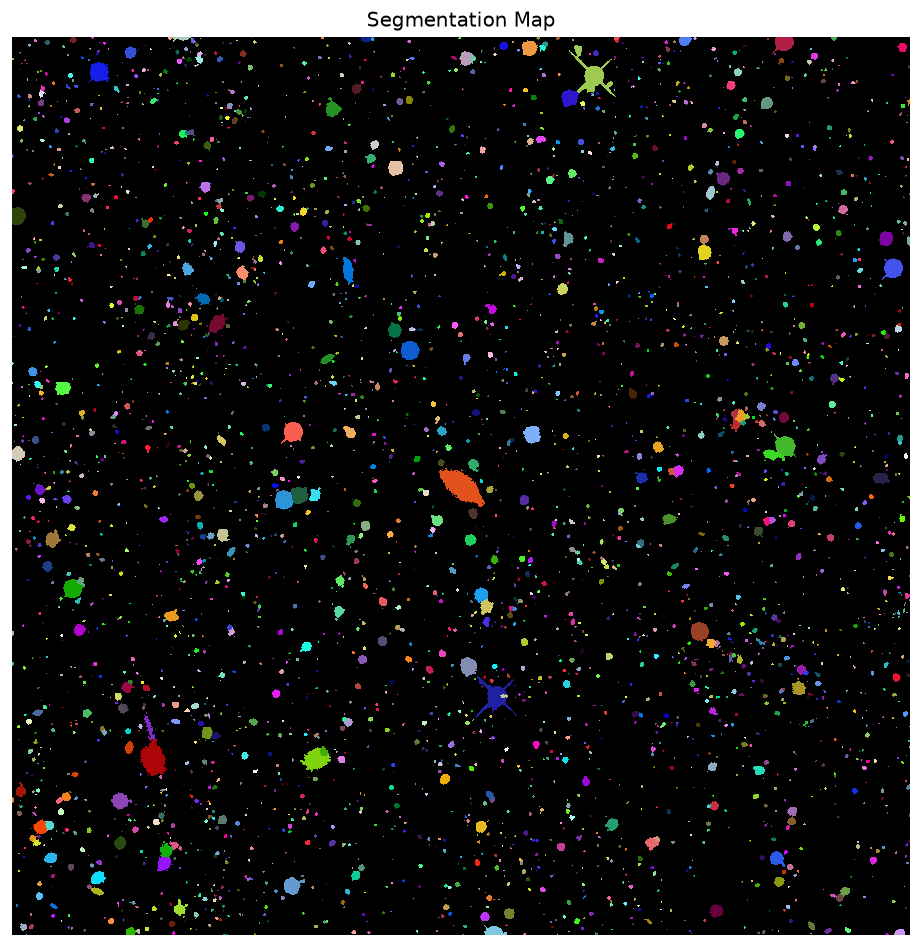

In [5]:
# Inspect the segmentation map
plot_segment(RAW_SEG_FILE, os.path.join(OUTPUT_DIR, "segment_plot_raw.png"))
display(Image(os.path.join(OUTPUT_DIR, "segment_plot_raw.png")))

## Build Source Mask with mask_poly_expand
Here we use a tool from Shangguan which expands a mask by a given factor.

In [6]:
# Segmentation map is usually insufficient to mask the outskirts of the sources, here we expand the segmentation mask with mask_poly_expand function.
# You can find the mask_poly_expand function in https://github.com/jyshangguan/astro_image_mask_tools
seg_for_mask = fits.getdata(RAW_SEG_FILE)
source_mask = mask_poly_expand(seg_for_mask > 0, factor=1.5)

wht = fits.getdata(WHT_FILE)
source_mask |= (wht <= 0)          # Also mask pixels with negative weights.

print(f"Source mask: {source_mask.sum()} / {source_mask.size} "
      f"pixels masked ({source_mask.sum()/source_mask.size * 100:.1f}%)")

Source mask: 976208 / 7551504 pixels masked (12.9%)


## Background Subtraction

Modeling background (box=16, filter=(3, 3))...
  Done in 3.5s, bkg median=0.0000, RMS=0.0023
  Sigma propagated: sqrt(sigma² + bkg_rms²), saved to ./output/sigma_sub.fits
Background comparison saved to ./output/background_subtraction.png
  sci_sub saved to ./output/sci_subtracted.fits


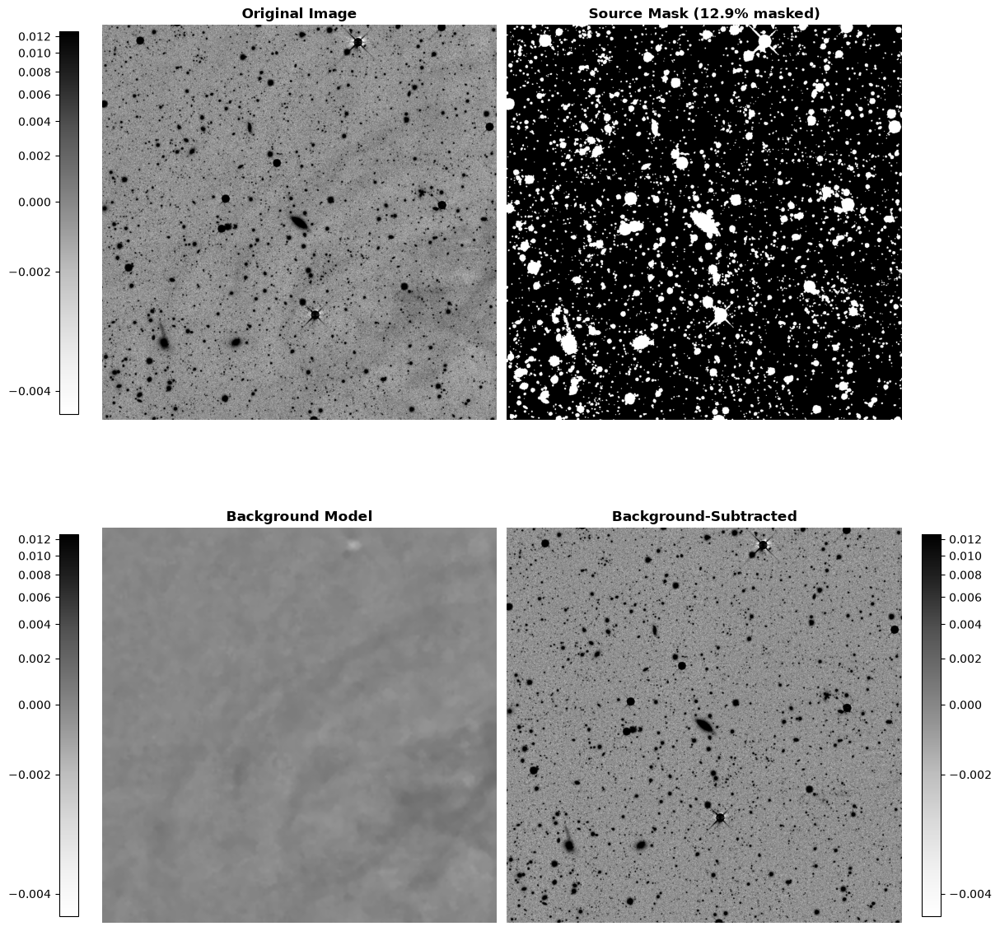

In [7]:
# Remove the background. Background is harmful to building stacked PSF, especially for faint stars. 
sci_orig = fits.getdata(SCI_IMAGE)
sci_sub, bkg_model, bkg_rms, _ = subtract_background(
    sci_orig, source_mask,
    output_dir=OUTPUT_DIR,
    bkg_box_size=BKG_BOX_SIZE,
    bkg_filter_size=BKG_FILTER_SIZE,
)

# Propagate background uncertainty into sigma
sigma_file = os.path.join(DATA_DIR, "sigma_r.fits")
if os.path.exists(sigma_file):
    sigma_orig = fits.getdata(sigma_file)
    sigma_new = np.zeros_like(sigma_orig, dtype=float)
    good = sigma_orig > 0
    sigma_new[good] = np.sqrt(sigma_orig[good] ** 2 + bkg_rms[good] ** 2)      # Propagate the background uncertainty into sigma.    
    SIGMA_SUB_FILE = os.path.join(OUTPUT_DIR, "sigma_sub.fits")
    fits.writeto(SIGMA_SUB_FILE, sigma_new, fits.getheader(sigma_file), overwrite=True)
    print(f"  Sigma propagated: sqrt(sigma² + bkg_rms²), saved to {SIGMA_SUB_FILE}")

plot_background(sci_orig, bkg_model, sci_sub, source_mask,
                os.path.join(OUTPUT_DIR, "background_subtraction.png"))

## Insepect your background subtraction results. 
SCI_SUB_IMAGE = os.path.join(OUTPUT_DIR, "sci_subtracted.fits")
fits.writeto(SCI_SUB_IMAGE, sci_sub, fits.getheader(SCI_IMAGE), overwrite=True)
print(f"  sci_sub saved to {SCI_SUB_IMAGE}")
display(Image(os.path.join(OUTPUT_DIR, "background_subtraction.png")))

The four panels above show the original image, source mask, background model, and background-subtracted image. Check whether the mask fully covers the sources, whether the background model is smooth, and whether any background residuals remain.

## 2nd SExtractor — on Background-Subtracted Image
In this step we detect sources on the background-subtracted image to get more accurate measurements. We'll use these results to select stars for building the stacked PSF.

[GX_CSEG] background 0.22s  var_setup 0.00s  ring_alloc 0.00s  scan 1.24s  segpaint 0.01s  labelstats 0.01s  outputs 0.12s
[GX_CSEG] 4010 detections -> 3627 objects
[GX_CSEG] assembled 3627 objects -> ./output/SEx/sex_out.cat
2nd SEx segmentation saved to ./output/SEx/sex_out_seg.fits
Segment plot saved to ./output/segment_plot.png


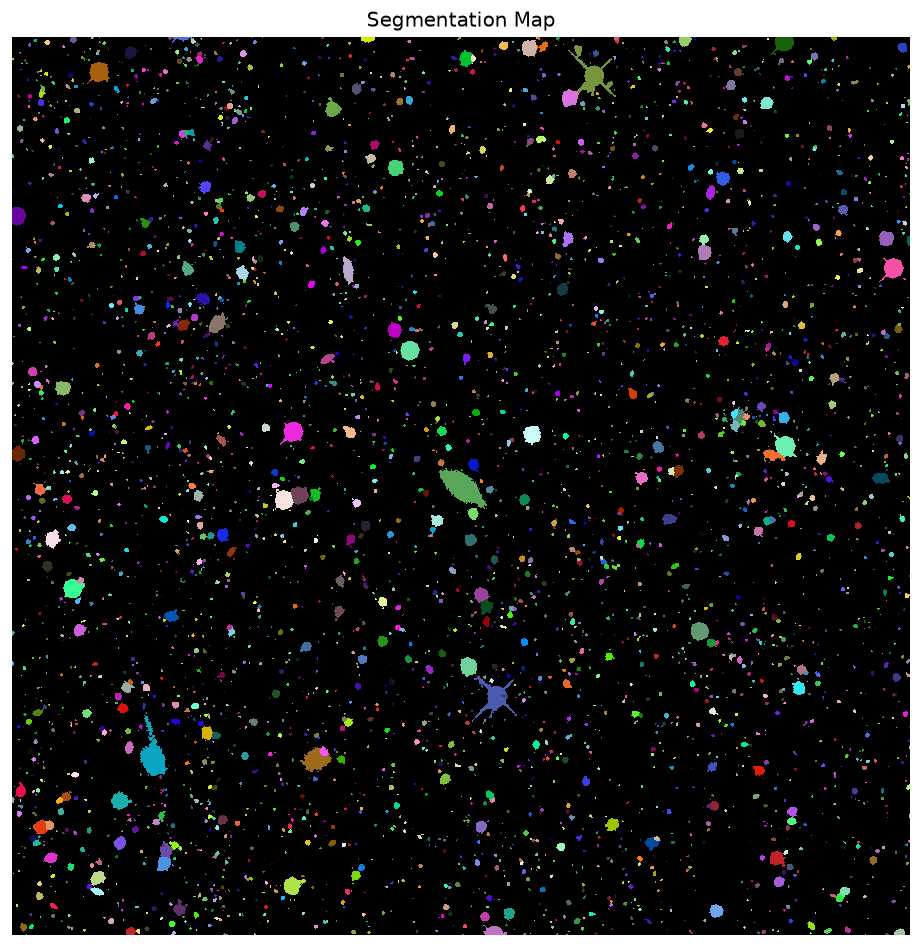

In [8]:
# Iterate the source detection on the background-subtracted image to detect fainter sources.
SEX_DIR_SUB = os.path.join(OUTPUT_DIR, "SEx")
os.makedirs(SEX_DIR_SUB, exist_ok=True)
CATALOG_FILE = os.path.join(SEX_DIR_SUB, "sex_out.cat")
SEG_FILE     = os.path.join(SEX_DIR_SUB, "sex_out_seg.fits")

catalog, segm, src_cat = SExtractor(
    filename=SCI_SUB_IMAGE,
    catalog_name=CATALOG_FILE,
    kernel=SEX_KERNEL,
    detect_minarea=DETECT_MINAREA,
    detect_thresh=1.0,                  # We can use a lower detection threshold for the background-subtracted image to detect fainter sources.
    deblend=True,
    deblend_nthresh=DEBLEND_NTHRESH,
    deblend_mincont=DEBLEND_MINCONT,
    clean=True,
    back_type=False,
    weight_type='MAP_WEIGHT',
    weight_name=WHT_CLIP_FILE,
    mag_zeropoint=MAG_ZEROPOINT,
    pixel_scale=PIXEL_SCALE,
    fwhm_arcsec=FWHM_ARCSEC,
    verbose=True,
)
hdr = fits.getheader(SCI_IMAGE)
seg_data = segm.data.astype(np.int32)
fits.writeto(SEG_FILE, seg_data, hdr, overwrite=True)
print(f"2nd SEx segmentation saved to {SEG_FILE}")
plot_segment(SEG_FILE, os.path.join(OUTPUT_DIR, "segment_plot.png"))
display(Image(os.path.join(OUTPUT_DIR, "segment_plot.png")))

## select_valid_stars — SEx catalog
Here we select stars that satisfy the morphology criteria above.

In [9]:
# Try to adjust the selection criteria to select more stars. You can adjust the parameters above to select more stars.
morphology_results = select_valid_stars(
    CATALOG_FILE,
    seg_file=SEG_FILE,
    elongation_limit=ELONG_LIMIT,
    class_star_limit=CLASS_STAR_LIMIT,
    combined_flags_limit=COMBINED_FLAGS_LIMIT,
    mag_bright_limit=MAG_BRIGHT,
    mag_faint_limit=MAG_FAINT,
    SNR_limit=SNR_LIMIT,
    cutout_size=CUTOUT_SIZE,
    skip_bright_neighbors=True,
    mag_gap_limit=MAG_GAP_LIMIT,
    verbose=False,
)
ascii.write(morphology_results, os.path.join(OUTPUT_DIR, "morphology_selected.ecsv"), overwrite=True)
valid_ids = [int(x) for x in morphology_results['label']]
print(f"Satisfy morphology criteria: {len(valid_ids)} sources.")

85 sources satisfy stellar criteria (elong<1.2, class_star>0.9, combined_flags<1, mag 17.0-22.0, SNR>0.0)
Satisfy morphology criteria: 85 sources.


## Cutout Stars

  Cutout: 85 stamps
    Saved to ./output/cutouts/
Stars image saved to ./output/selected_stars_image.png
Cutout: 85 stamps


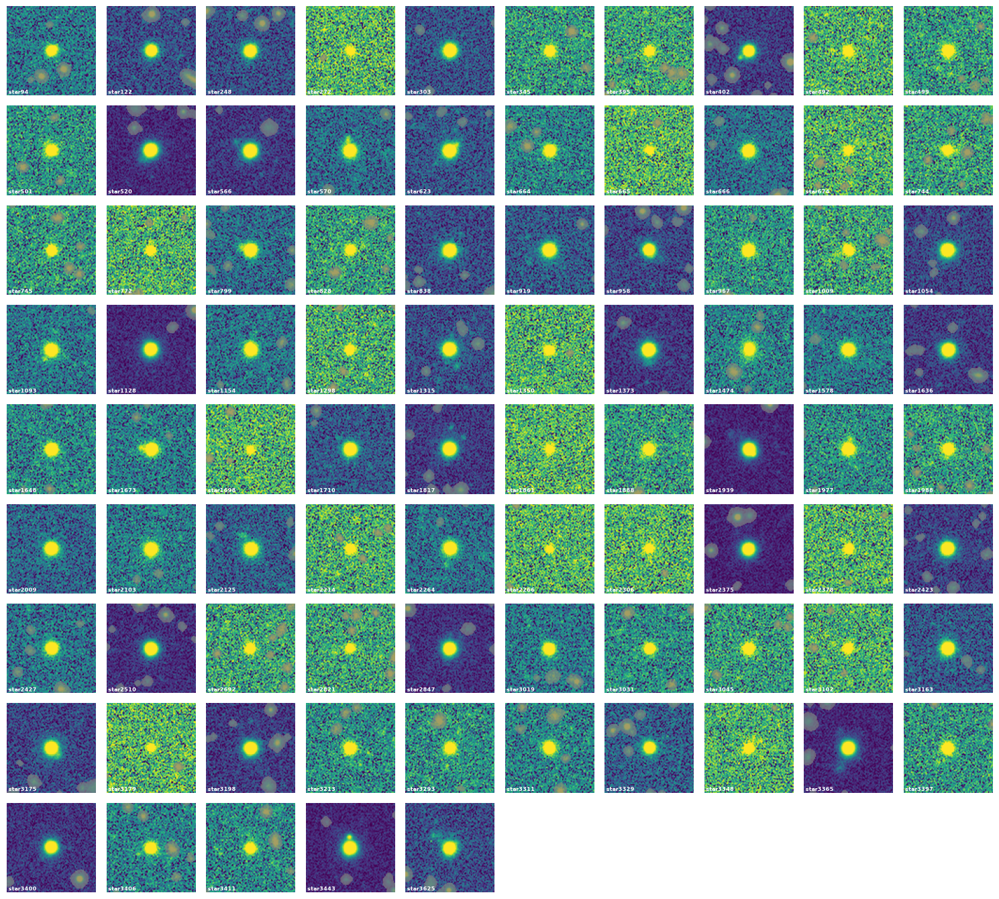

In [10]:
cut_valid_ids, sci_cuts, mask_list, valid_coords, sig_cuts = cutout_stars(
    sci_image=sci_sub,
    seg_file=SEG_FILE,
    catalog_file=CATALOG_FILE,
    star_ids=valid_ids,
    output_dir=OUTPUT_DIR,
    cutout_size=CUTOUT_SIZE,
    save_cutouts=True,
    sigma_image=SIGMA_SUB_FILE,
)
print(f"Cutout: {len(cut_valid_ids)} stamps")
# Inspect the cutouts of the selected stars and their mask overlays.
display(Image(os.path.join(OUTPUT_DIR, "selected_stars_image.png")))

## Build Stacked PSF (Morphology Selection)

In [11]:
psf_basic = stacked_psf_pipeline(
    sci_image=SCI_SUB_IMAGE,
    catalog_file=CATALOG_FILE,
    seg_file=SEG_FILE,
    output_dir=OUTPUT_DIR,
    elongation_limit=ELONG_LIMIT,
    class_star_limit=CLASS_STAR_LIMIT,
    mag_bright_limit=MAG_BRIGHT,
    mag_faint_limit=MAG_FAINT,
    SNR_limit=SNR_LIMIT,
    cutout_size=CUTOUT_SIZE,
    oversampling=OVERSAMPLING,
    subtract_bkg=False,
    sigma_image=SIGMA_SUB_FILE,
    star_ids=valid_ids,
    pixel_scale=PIXEL_SCALE,
    plot_stamps=True,
    plot_radial=True,
    plot_psf_img=True,
    plot_scatter=True,
    plot_over=True,
    psf_output_name="psf_basic.fits",
)
psf_basic = psf_basic[0]       # extract file path from returned tuple
print(f"PSF: {psf_basic}")

  Cutout: 85 stamps
    Saved to ./output/cutouts/
Stars image saved to ./output/selected_stars_image.png
PSF saved: ./output/psf_basic.fits
Overview image saved to ./output/selected_stars_overview.png
Stars scatter saved to ./output/stars_scatter_diagnostics.png
Radial profile plot saved to ./output/stars_radial_profiles.png
PSF image saved to ./output/stacked_psf.png
PSF: ./output/psf_basic.fits


## Basic Results

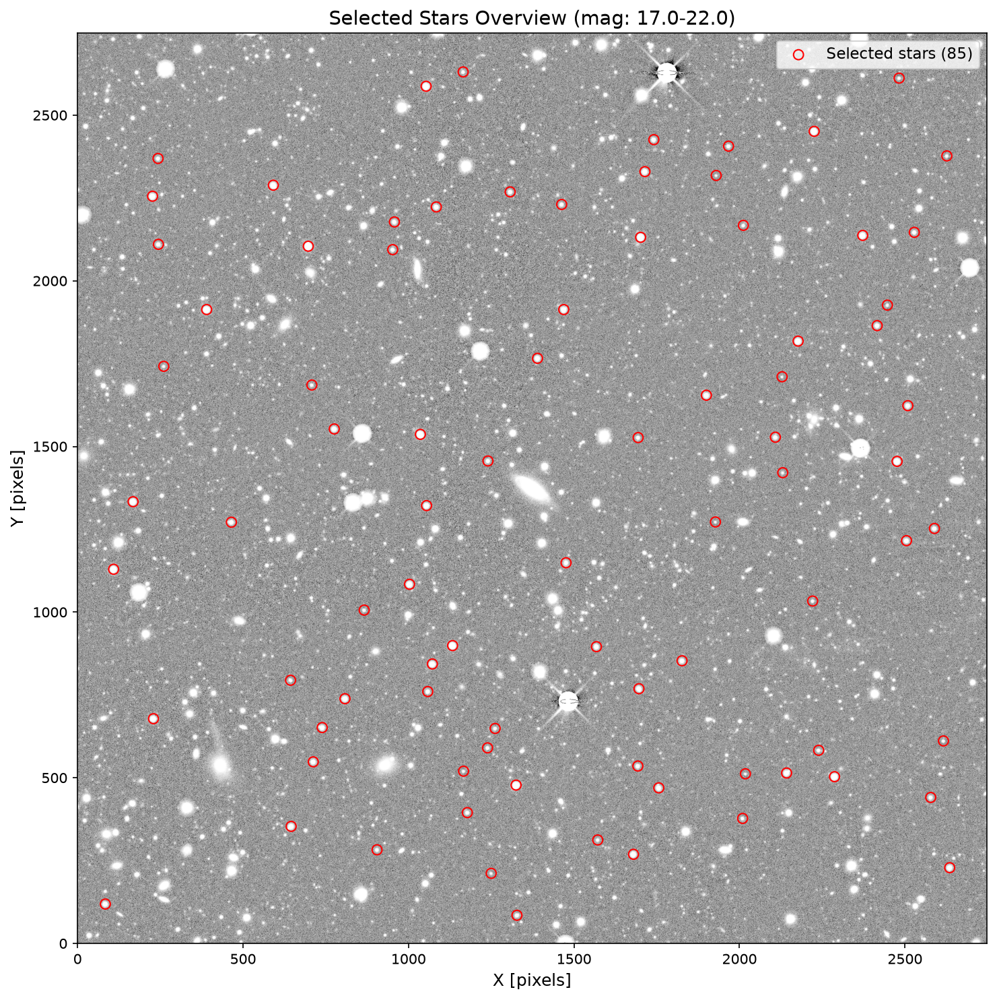

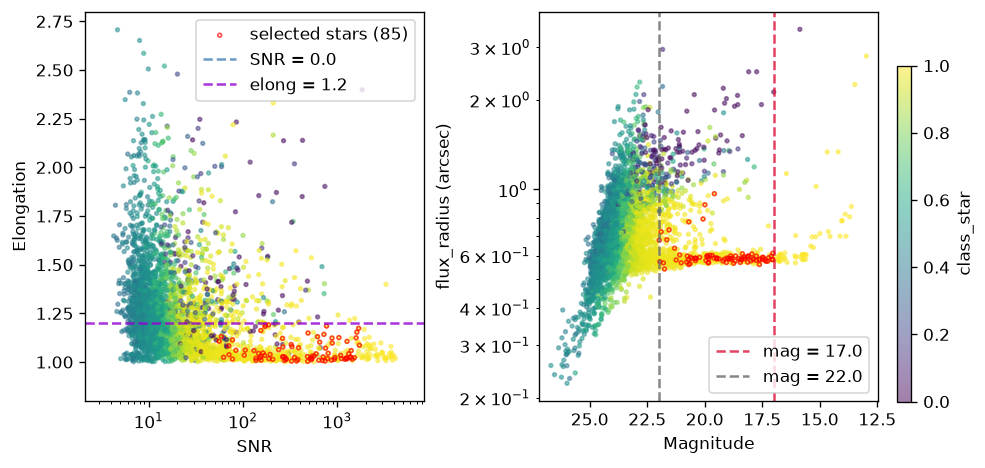

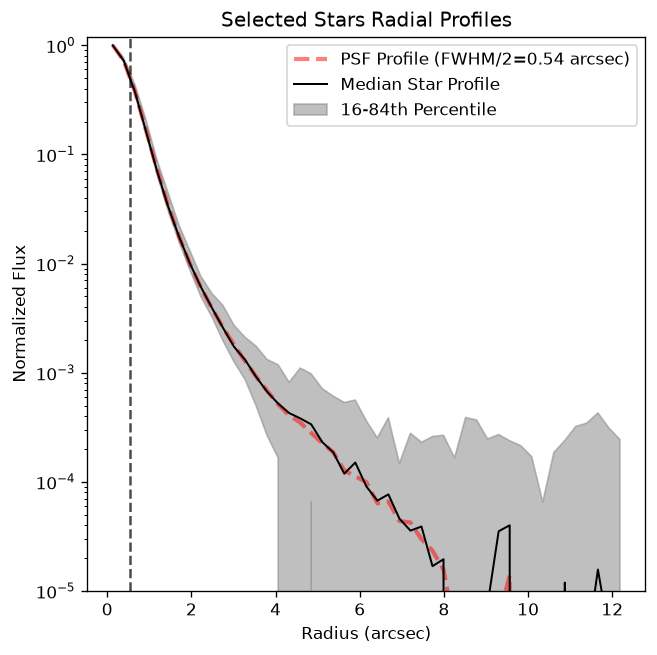

In [12]:
## Inspect diagnostics of the selected stars and the stacked PSF results.
display(Image(os.path.join(OUTPUT_DIR, "selected_stars_overview.png")))
display(Image(os.path.join(OUTPUT_DIR, "stars_scatter_diagnostics.png")))
display(Image(os.path.join(OUTPUT_DIR, "stars_radial_profiles.png")))

Overview Image — It shows the selected stars distribution in the field.

Scatter Diagnostics Image — It shows physical parameters of all the sources and selected stars. Note that on the right panel, the selected stars' flux radius should be on the same branch.

Stars Radial Profile Image — It shows the selected stars and stacked PSF 1D profiles. Importantly, because the y-axis is in log scale, the outer profile of the stacked PSF should wiggle up and down (noise-dominated).

## Gaia Crossmatch + Quality Filter
For DESI Legacy Survey, we cross match the catalog with Gaia DR3 and select stars by three quality criteria:

**RUWE** (Renormalised Unit Weight Error) — It measures how well the single-star model fits the Gaia astrometry. RUWE < 1.4 typically means a good astrometric solution; RUWE > 1.4 could indicate unresolved binaries or problematic measurements.

**IPDfmp** (Image Parameter Determination fraction of multi-peak) — It flags sources with multiple peaks in the Gaia window image. IPDfmp == 0 means a single clean source; > 0 means likely blending with a neighbour.

**classprob_dsc_combmod_star** — Gaia DR3's DSC (Discrete Source Classification) provides the probability that a source is a single star rather than a galaxy or quasar. We require > 0.9 to reject galaxies and quasars.

This step selects true stars, rather than relying only on the morphology criteria above.

In [13]:
RUWE_LIMIT    = 1.4    # RUWE < 1.4 — good astrometric solution
IPDFMP_VAL    = 0      # IPDfmp == 0 — single-peaked (not blended)
CLASSPROB_LIM = 0.9    # DSC classprob > 0.9 — high-confidence star

gaia_matched = gaia_crossmatch(os.path.join(OUTPUT_DIR, "morphology_selected.ecsv"), max_distance=0.5, verbose=False)
ascii.write(Table.from_pandas(gaia_matched), os.path.join(OUTPUT_DIR, "gaia_matched.ecsv"), overwrite=True)
print(f"Gaia crossmatch: {len(gaia_matched)} sources matched")

fltr = ((gaia_matched["RUWE"] < RUWE_LIMIT)
        & (gaia_matched["IPDfmp"] == IPDFMP_VAL)
        & (gaia_matched["classprob_dsc_combmod_star"] > CLASSPROB_LIM))
gaia_selected = gaia_matched[fltr]
print(f"After Gaia quality cuts: {len(gaia_selected)} sources")

gaia_selected_ids = [int(x) for x in gaia_selected["label"]]
selected_gaia = select_valid_stars(
    CATALOG_FILE,
    seg_file=SEG_FILE,
    elongation_limit=ELONG_LIMIT,
    class_star_limit=CLASS_STAR_LIMIT,
    combined_flags_limit=COMBINED_FLAGS_LIMIT,
    mag_bright_limit=MAG_BRIGHT,
    mag_faint_limit=MAG_FAINT,
    SNR_limit=SNR_LIMIT,
    cutout_size=CUTOUT_SIZE,
    skip_bright_neighbors=True,
    select_ids=gaia_selected_ids,
    verbose=False,
)
ascii.write(Table.from_pandas(gaia_selected), os.path.join(OUTPUT_DIR, "gaia_selected.ecsv"), overwrite=True)
valid_ids_gaia = [int(x) for x in selected_gaia["label"]]
print(f"Gaia-filtered valid stars: {len(valid_ids_gaia)}")

The current archive release 3.15 contains two breaking changes. Please see https://www.cosmos.esa.int/web/gaia/news#GACSrelease315 for details. In case of questions or feedback, please consult the Gaia helpdesk at https://www.cosmos.esa.int/web/gaia/gaia-helpdesk.
INFO: Query finished. [astroquery.utils.tap.core]
Gaia ESA: 508 sources in field
Gaia crossmatch (ESA): 75/85 matched
INFO: Query finished. [astroquery.utils.tap.core]
Gaia crossmatch: 75 sources matched
After Gaia quality cuts: 60 sources
42 sources satisfy stellar criteria (elong<1.2, class_star>0.9, combined_flags<1, mag 17.0-22.0, SNR>0.0)
Gaia-filtered valid stars: 42


## Build Stacked PSF (Gaia selection)

In [14]:
GAIA_OUT = os.path.join(OUTPUT_DIR, "gaia_selection")
os.makedirs(GAIA_OUT, exist_ok=True)
psf_gaia = stacked_psf_pipeline(
    sci_image=SCI_SUB_IMAGE,
    catalog_file=CATALOG_FILE,
    seg_file=SEG_FILE,
    output_dir=GAIA_OUT,
    elongation_limit=ELONG_LIMIT,
    class_star_limit=CLASS_STAR_LIMIT,
    mag_bright_limit=MAG_BRIGHT,
    mag_faint_limit=MAG_FAINT,
    SNR_limit=SNR_LIMIT,
    cutout_size=CUTOUT_SIZE,
    oversampling=OVERSAMPLING,
    subtract_bkg=False,
    sigma_image=SIGMA_SUB_FILE,
    star_ids=valid_ids_gaia,
    pixel_scale=PIXEL_SCALE,
    plot_stamps=True,
    plot_radial=True,
    plot_psf_img=True,
    plot_scatter=True,
    plot_over=True,
    psf_output_name="psf_gaia.fits",
)
psf_gaia = psf_gaia[0]
print(f"Gaia PSF: {psf_gaia}")

  Cutout: 42 stamps
    Saved to ./output/gaia_selection/cutouts/
Stars image saved to ./output/gaia_selection/selected_stars_image.png
PSF saved: ./output/gaia_selection/psf_gaia.fits
Overview image saved to ./output/gaia_selection/selected_stars_overview.png
Stars scatter saved to ./output/gaia_selection/stars_scatter_diagnostics.png
Radial profile plot saved to ./output/gaia_selection/stars_radial_profiles.png
PSF image saved to ./output/gaia_selection/stacked_psf.png
Gaia PSF: ./output/gaia_selection/psf_gaia.fits


## Gaia Results

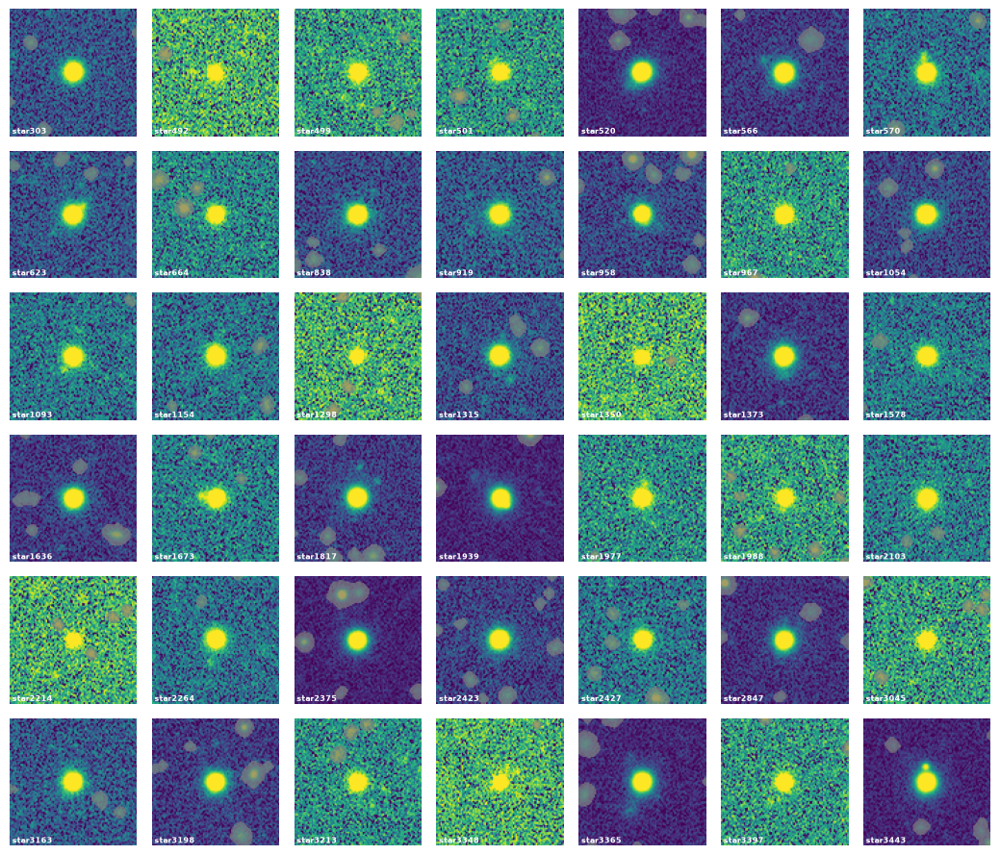

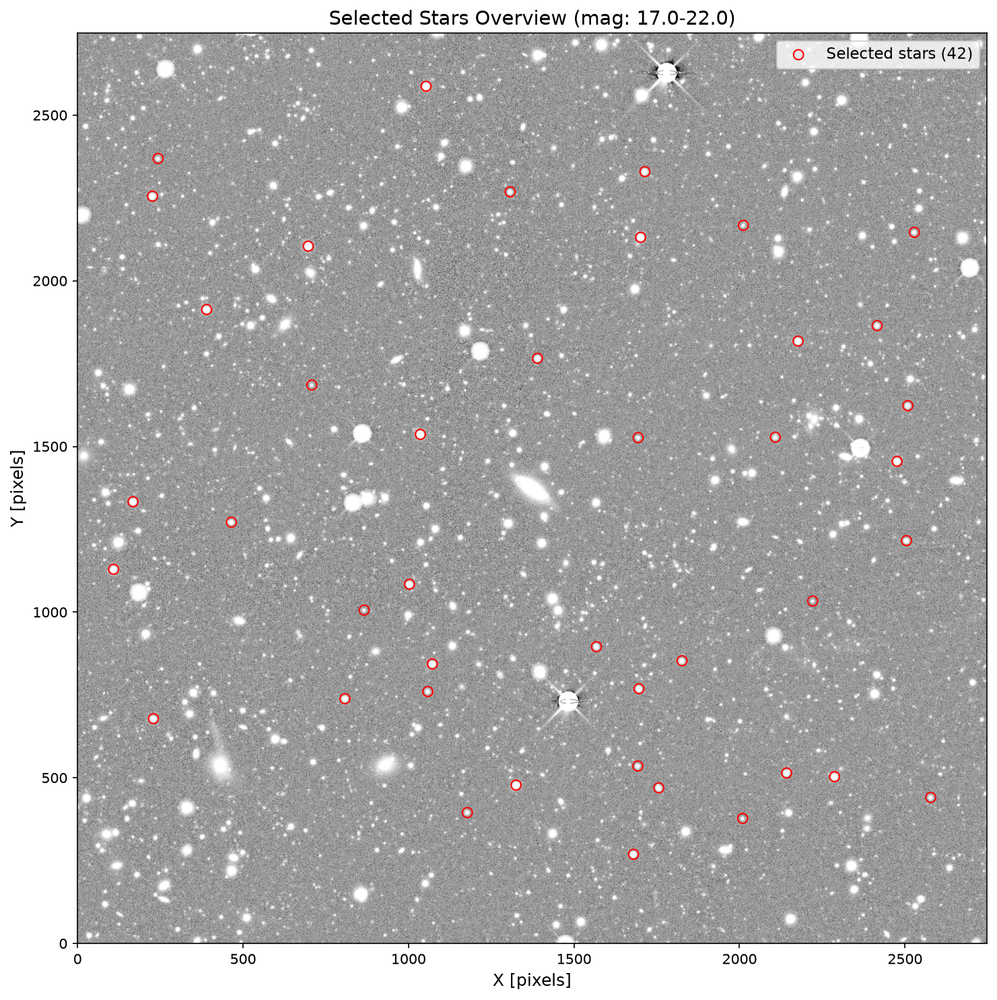

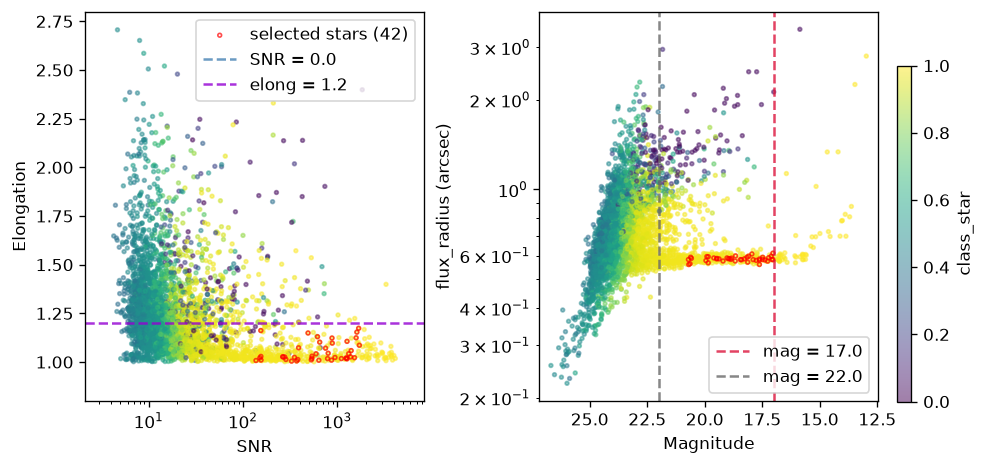

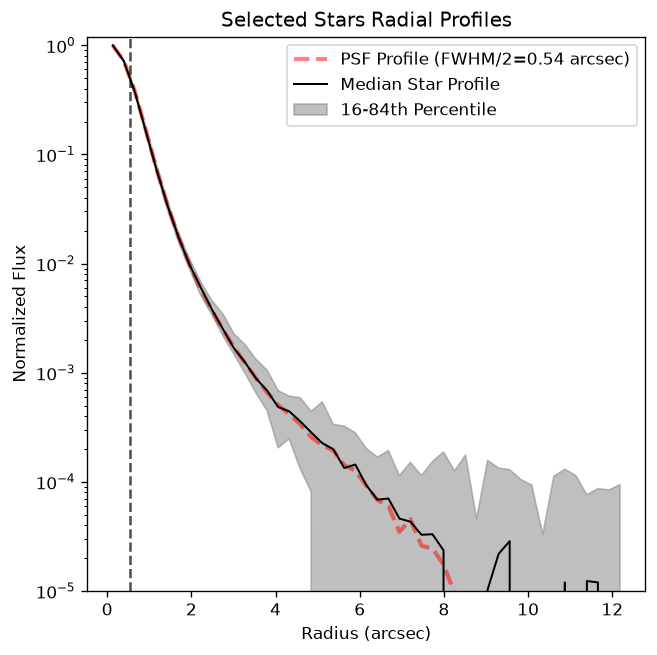

In [15]:
display(Image(os.path.join(GAIA_OUT, "selected_stars_image.png")))
display(Image(os.path.join(GAIA_OUT, "selected_stars_overview.png")))
display(Image(os.path.join(GAIA_OUT, "stars_scatter_diagnostics.png")))
display(Image(os.path.join(GAIA_OUT, "stars_radial_profiles.png")))

## Compare Both PSFs
Here we simply compare the two PSF images.

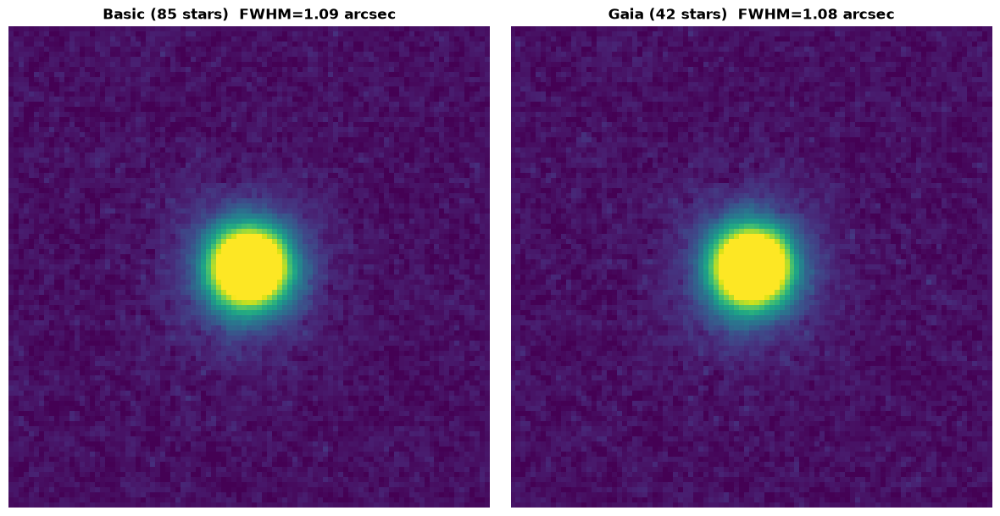

In [16]:
from photutils.psf import fit_fwhm
psf_b = fits.getdata(psf_basic)
psf_g = fits.getdata(psf_gaia)
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, psf, title in [(axes[0], psf_b, f"Basic ({len(valid_ids)} stars)"),
                         (axes[1], psf_g, f"Gaia ({len(valid_ids_gaia)} stars)")]:
    fwhm = fit_fwhm(psf)[0] * PIXEL_SCALE
    norm = simple_norm(psf, "asinh", vmin=np.percentile(psf, 5),
                       vmax=np.percentile(psf, 98.5))
    ax.imshow(psf, origin="lower", cmap="viridis", norm=norm)
    ax.set_title(f"{title}  FWHM={fwhm:.2f} arcsec", fontsize=12, fontweight="bold")
    ax.axis("off")
plt.tight_layout()
plt.show()